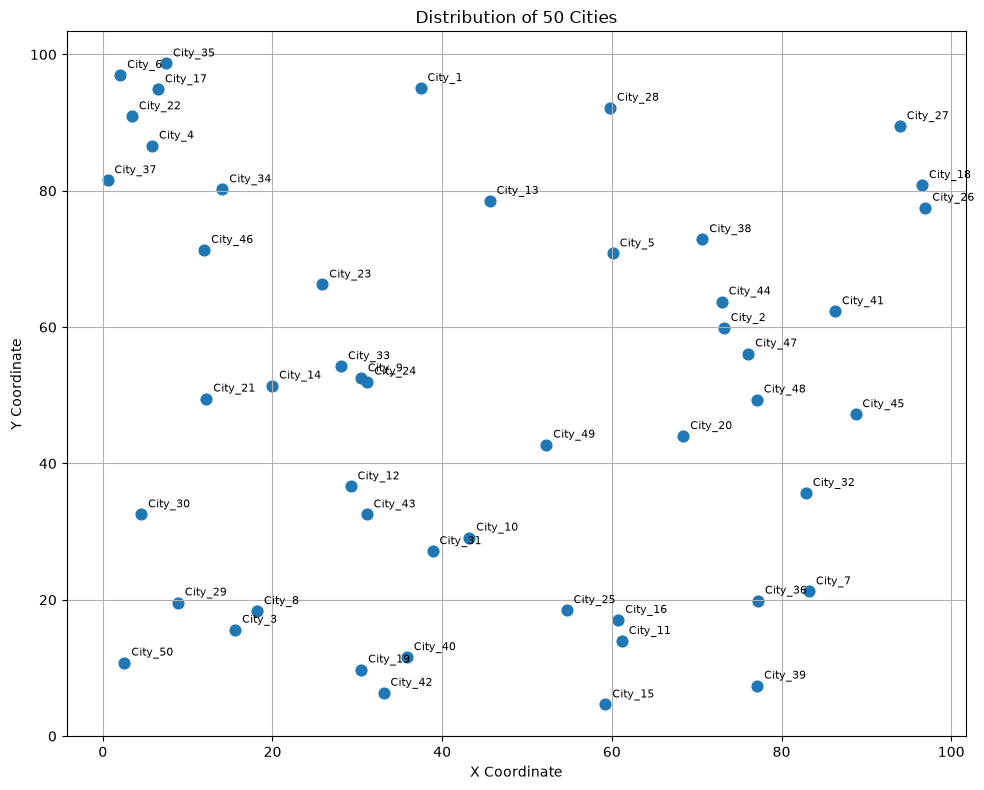

In [ ]:

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd


# Locate the dataset
project_root = Path.cwd().parent

dataset_path = (
    project_root / "data" / "raw" / "cities.csv"
)

cities = pd.read_csv(dataset_path)


# Create a scatter plot
plt.figure(figsize=(10, 8))

plt.scatter(
    cities["X"],
    cities["Y"],
    s=60,
    marker="o"
)

# Add city labels
for _, city in cities.iterrows():
    plt.annotate(
        city["City"],
        (city["X"], city["Y"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title("Distribution of 50 Cities")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.grid(True)
plt.tight_layout()
plt.show()



We want to understand:
- Whether the cities are distributed randomly or clustered.
- Whether some cities are far away from the others.
- Whether the coordinates occupy a similar range.
- Whether there are isolated cities that might make the route longer.
This matters because the spatial distribution can influence how difficult the TSP instance is for SA and GA.

In [4]:
from pathlib import Path
import pandas as pd
import sys

# Find the project root
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Add project root to Python module search path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("Source directory exists:", (project_root / "src").exists())

from src.data_loader import load_cities, validate_cities

# Load dataset
dataset_path = project_root / "data" / "raw" / "cities.csv"

cities = load_cities(dataset_path)

# Validate dataset
validate_cities(cities)

Project root: C:\Users\kasun\Desktop\projects\tsp-search-optimisation
Source directory exists: True
Dataset validation successful.


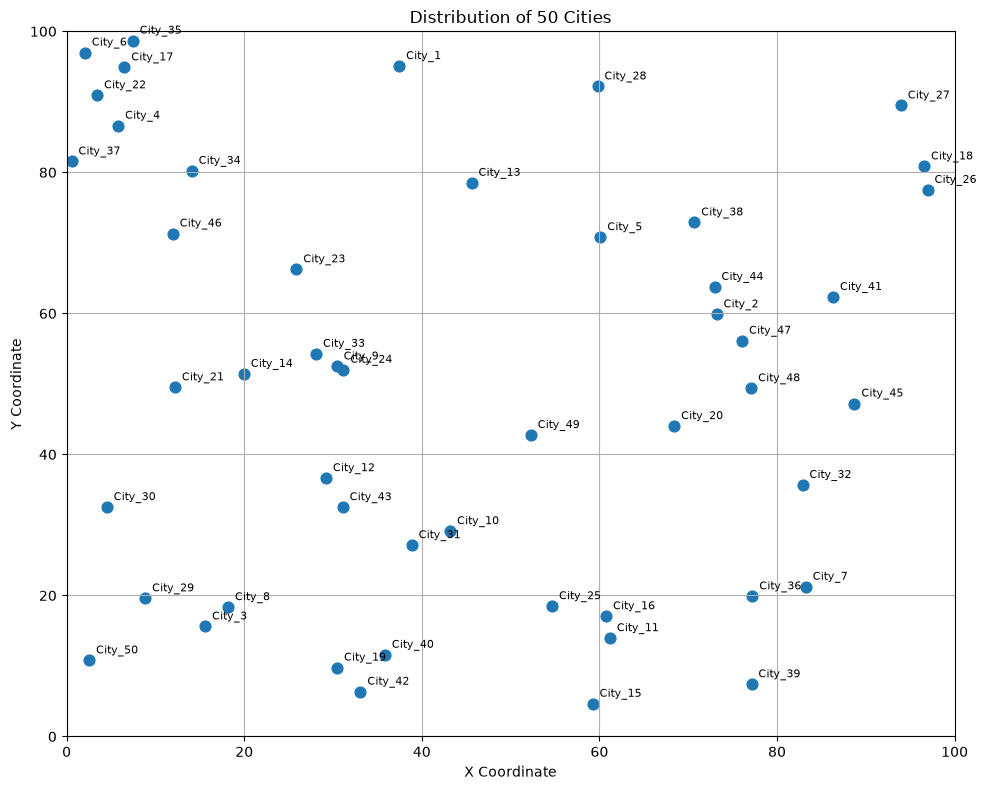

Duplicate coordinate locations:
Empty DataFrame
Columns: [City, X, Y]
Index: []
Number of duplicate coordinate locations: 0


In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.scatter(
    cities["X"],
    cities["Y"],
    s=60,
    marker="o"
)

# Label each city
for _, city in cities.iterrows():
    plt.annotate(
        city["City"],
        (city["X"], city["Y"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title("Distribution of 50 Cities")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.grid(True)
plt.tight_layout()
plt.show()

duplicate_coordinates = cities[
    cities.duplicated(
        subset=["X", "Y"],
        keep=False
    )
]

print("Duplicate coordinate locations:")
print(duplicate_coordinates)

print(
    "Number of duplicate coordinate locations:",
    len(duplicate_coordinates)
)

In [7]:
import numpy as np
import pandas as pd

from src.distance import calculate_distance_matrix

# Create a small test dataset
sample_cities = pd.DataFrame({
    "City": ["A", "B", "C"],
    "X": [0, 3, 0],
    "Y": [0, 4, 5]
})

# Calculate distances
sample_matrix = calculate_distance_matrix(sample_cities)

print("Distance Matrix:")
print(sample_matrix)

print("\nMatrix Shape:")
print(sample_matrix.shape)

Distance Matrix:
[[0.         5.         5.        ]
 [5.         0.         3.16227766]
 [5.         3.16227766 0.        ]]

Matrix Shape:
(3, 3)


In [9]:
from src.distance import calculate_distance_matrix

# Calculate the full distance matrix
distance_matrix = calculate_distance_matrix(cities)

print("========== DISTANCE MATRIX RESULTS ==========")

print("Matrix shape:", distance_matrix.shape)

print("Number of distances:", distance_matrix.size)

print("Minimum distance:", distance_matrix.min())

print("Maximum distance:", distance_matrix.max())

print("Mean distance:", distance_matrix.mean())

print("Matrix is symmetric:",
      np.allclose(distance_matrix, distance_matrix.T))

print("Diagonal contains zeros:",
      np.allclose(np.diag(distance_matrix), 0))

distance_df = pd.DataFrame(
    distance_matrix,
    index=cities["City"],
    columns=cities["City"]
)

display(distance_df.round(2))

========== DISTANCE MATRIX RESULTS ==========
Matrix shape: (50, 50)
Number of distances: 2500
Minimum distance: 0.0
Maximum distance: 120.61550710716688
Mean distance: 52.74043340711027
Matrix is symmetric: True
Diagonal contains zeros: True


City,City_1,City_2,City_3,City_4,City_5,City_6,City_7,City_8,City_9,City_10,...,City_41,City_42,City_43,City_44,City_45,City_46,City_47,City_48,City_49,City_50
City,,,,,,,,,,,,,,,,,,,,,
City_1,0.00,50.17,82.42,32.76,33.20,35.45,86.88,79.11,43.17,66.20,...,58.81,88.82,62.88,47.34,70.13,34.84,54.85,60.49,54.38,91.23
City_2,50.17,0.00,72.64,72.51,17.06,80.25,39.92,68.93,43.41,42.96,...,13.34,66.87,50.20,3.90,20.02,62.30,4.72,11.19,27.03,86.03
City_3,82.42,72.64,0.00,71.69,70.92,82.51,67.88,3.76,39.74,30.73,...,84.76,19.78,22.94,74.89,79.66,55.84,72.80,70.16,45.63,13.92
City_4,32.76,72.51,71.69,0.00,56.56,11.03,101.35,69.39,42.09,68.58,...,84.09,84.77,59.72,70.94,91.80,16.48,76.60,80.43,63.90,75.90
City_5,33.20,17.06,70.92,56.56,0.00,63.68,54.71,67.16,34.89,44.99,...,27.54,69.89,48.04,14.66,37.08,48.15,21.69,27.34,29.13,83.17
City_6,35.45,80.25,82.51,11.03,63.68,0.00,111.04,80.29,52.78,79.36,...,91.10,95.80,70.71,78.31,99.94,27.51,84.55,88.87,73.91,86.20
City_7,86.88,39.92,67.88,101.35,54.71,111.04,0.00,65.13,61.37,40.82,...,41.21,52.31,53.35,43.75,26.56,87.12,35.62,28.81,37.71,81.38
City_8,79.11,68.93,3.76,69.39,67.16,80.29,65.13,0.00,36.26,27.24,...,81.10,19.13,19.18,71.16,76.22,53.35,69.14,66.59,41.93,17.37
City_9,43.17,43.41,39.74,42.09,34.89,52.78,61.37,36.26,0.00,26.62,...,56.75,46.20,19.97,44.01,58.53,26.39,45.80,46.78,23.91,50.15


What does symmetric mean?

The distance from City A to City B must be equal to the distance from City B to City A.
\[
d(A,B)=d(B,A)
\]


Why should the diagonal contain zeros?

The diagonal represents the distance from each city to itself.

For example:
\[
d(A,A)=0
\]

A city has zero distance from itself.

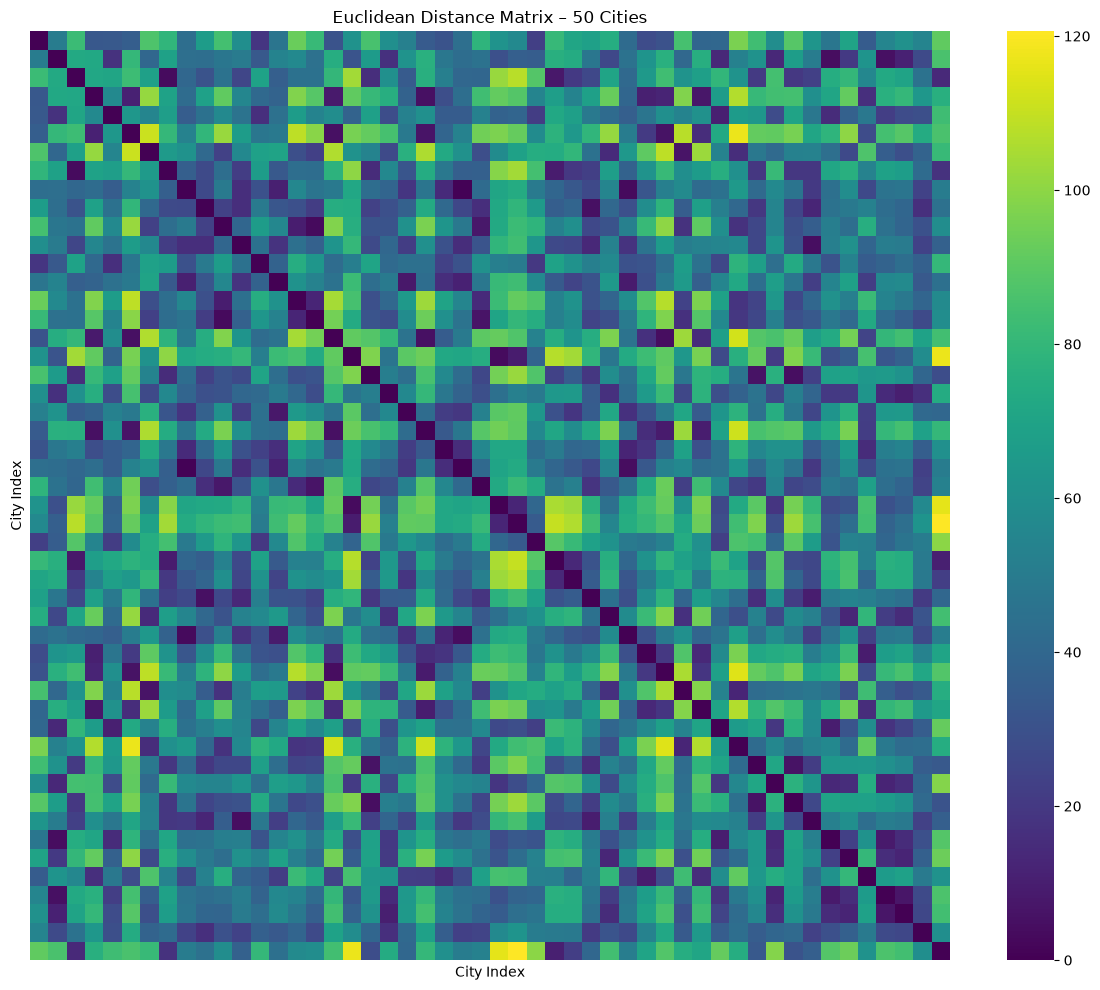

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))

sns.heatmap(
    distance_matrix,
    cmap="viridis",
    xticklabels=False,
    yticklabels=False
)

plt.title("Euclidean Distance Matrix – 50 Cities")
plt.xlabel("City Index")
plt.ylabel("City Index")

plt.tight_layout()
plt.show()

In [ ]:
def calculate_route_distance(
    route: list[int],
    distance_matrix: np.ndarray
) -> float:
    """Calculate the total distance of a closed TSP route."""

    return float(
        sum(
            distance_matrix[route[i], route[i + 1]]
            for i in range(len(route) - 1)
        )
    )
    

In [12]:
from src.distance import calculate_distance_matrix
from src.route_evaluator import calculate_route_distance

# Calculate the distance matrix
distance_matrix = calculate_distance_matrix(cities)

# Create a simple route visiting cities in dataset order
route = list(range(len(cities)))

# Calculate total route distance
total_distance = calculate_route_distance(
    route,
    distance_matrix
)

print("Number of cities:", len(route))
print("Route:", route)
print("Total route distance:", total_distance)

Number of cities: 50
Route: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49]
Total route distance: 2663.9638330914204
